# Part C — Montréal towing regression

This notebook completes Step 4 of the team's final analysis plan using the supplied Part A data. It fits the three specified OLS models, compares training fit and held-out count accuracy, estimates borough snow slopes with confidence intervals, and translates them into a clearly defined extra-cars scenario.

**Run all cells in order.** Start Jupyter in the project folder or this `part_c` folder. Install the packages in `requirements.txt` if needed. Outputs are written beneath `part_c`; the original Part A CSV is preserved.

Train: **2021-01-01–2025-06-30**. Test: **2025-07-01–2026-06-30**. All models use the same rows. The test year is used for evaluation, never fitting or retransformation calibration.

Percent effects refer exactly to the model's **tows + 1** scale. They describe adjusted associations, rather than causal changes or individual driver probabilities. Conventional OLS intervals satisfy the planned analysis. A separate panel-robust interval check allows correlated boroughs and serial dependence.

In [1]:
from pathlib import Path
import os
os.environ['SM_FORMULA_ENGINE'] = 'patsy'
import hashlib, json, platform, sys, unicodedata, re
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import statsmodels
import scipy
import statsmodels.formula.api as smf
from patsy import build_design_matrices
from scipy import stats
from IPython.display import display, Image

pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 160)
pd.set_option('display.max_colwidth', 55)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p/'data/processed/tow_risk_clean.csv').exists()), None)
if ROOT is None:
    ROOT = next((p/'Tow_Risk_Project' for p in candidates if (p/'Tow_Risk_Project/data/processed/tow_risk_clean.csv').exists()), None)
assert ROOT is not None, 'Open the notebook from the project folder or its part_c subfolder.'
OUT = ROOT/'part_c'
for name in ['tables', 'figures', 'handoff']:
    (OUT/name).mkdir(parents=True, exist_ok=True)
SOURCE = ROOT/'data/processed/tow_risk_clean.csv'
data = pd.read_csv(SOURCE, encoding='utf-8-sig', parse_dates=['date']).sort_values(['date','borough']).reset_index(drop=True)
versions = {'python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__, 'scipy': scipy.__version__, 'statsmodels': statsmodels.__version__, 'matplotlib': matplotlib.__version__}
print('Packages:', versions)
print('Source SHA256:', hashlib.sha256(SOURCE.read_bytes()).hexdigest())
display(data.head())

Packages: {'python': '3.12.1', 'pandas': '2.2.3', 'numpy': '2.5.3', 'scipy': '1.17.0', 'statsmodels': '0.14.6', 'matplotlib': '3.9.2'}
Source SHA256: d3c99c238727b4475c4d5de991f2a69d9f47445ea25cdd13e867afba312434d4


,date,borough,tows,snow_7c,snow_8_14,snow_1,rain_1,temp_7,dow,month,trend,moving_day
0,2021-01-01,Ahuntsic-Cartierville,0,14.0,10.8,0.0,0.8,-1.828571,4,1,0.0,0
1,2021-01-01,Anjou,0,14.0,10.8,0.0,0.8,-1.828571,4,1,0.0,0
2,2021-01-01,Côte-des-Neiges–Notre-Dame-de-Grâce,0,14.0,10.8,0.0,0.8,-1.828571,4,1,0.0,0
3,2021-01-01,LaSalle,0,14.0,10.8,0.0,0.8,-1.828571,4,1,0.0,0
4,2021-01-01,Lachine,0,14.0,10.8,0.0,0.8,-1.828571,4,1,0.0,0


## 1 Validate the complete borough and day panel

Check keys, date coverage, calendar fields, numerical ranges and yearly totals before estimating anything. The 2026 total covers only January–June.

In [2]:
expected_dates = pd.date_range('2021-01-01','2026-06-30')
boroughs = sorted(data.borough.unique())
assert data.shape == (34119,12)
assert len(boroughs) == 17
assert not data.isna().any().any()
assert not data.duplicated(['date','borough']).any()
assert (data.groupby('date').size() == 17).all()
assert pd.DatetimeIndex(data.date.unique()).equals(expected_dates)
assert (data.groupby('borough').size() == len(expected_dates)).all()
assert data.tows.ge(0).all() and np.allclose(data.tows, np.round(data.tows))
assert data.snow_7c.between(0,30).all()
assert (data.dow == data.date.dt.dayofweek).all()
assert (data.month == data.date.dt.month).all()
assert (data.moving_day == ((data.date.dt.month == 7) & (data.date.dt.day == 1)).astype(int)).all()
assert np.allclose(data.trend, (data.date-pd.Timestamp('2021-01-01')).dt.days/365.25)
weather_cols = ['snow_7c','snow_8_14','snow_1','rain_1','temp_7']
assert (data.groupby('date')[weather_cols].nunique() == 1).all().all()
yearly = data.groupby(data.date.dt.year).tows.agg(['sum','size']).rename(columns={'sum':'tows','size':'borough_days'})
yearly.to_csv(OUT/'tables/data_yearly_totals.csv')
display(yearly)
print(f'Panel checks passed: {len(data):,} rows, {len(boroughs)} boroughs, {len(expected_dates):,} dates.')

,tows,borough_days
date,,
2021,43248,6205
2022,49765,6205
2023,45377,6205
2024,34210,6222
2025,63965,6205
2026,45676,3077


Panel checks passed: 34,119 rows, 17 boroughs, 2,007 dates.


## 2 Audit raw weather and avoid temperature look-ahead

Rebuild the Part A weather features from the seven raw annual weather files and verify that they reproduce the supplied CSV. Part A fills missing temperatures by interpolation between neighbouring dates. That can use temperatures measured on or after the towing day. For this forecasting exercise, replace this one feature with a past-only alternative: fill a missing daily temperature using the last observed temperature, then lag and take the seven-day mean. Do not change the original CSV. Export the exact model input for D.

If the raw towing file is present, also independently reconcile the borough/day counts. The same borough normalization and exclusions as Part A apply.

In [3]:
parts = []
for year in range(2020,2027):
    w = pd.read_csv(ROOT/f'montreal_weather_{year}.csv', encoding='utf-8-sig')
    w = w.rename(columns={'Date/Time':'date','Total Snow (cm)':'snow','Total Rain (mm)':'rain','Mean Temp (°C)':'temp'})
    w['date'] = pd.to_datetime(w['date'])
    parts.append(w.loc[w.date.dt.year.eq(year), ['date','snow','rain','temp']])
weather = pd.concat(parts).set_index('date').sort_index()
assert not weather.index.duplicated().any()
weather = weather.reindex(pd.date_range('2020-01-01','2026-06-30'))
for c in ['snow','rain','temp']:
    weather[c] = pd.to_numeric(weather[c],errors='coerce')
missing_weather = weather.isna().sum().to_dict()
weather[['snow','rain']] = weather[['snow','rain']].fillna(0)
rebuilt = pd.DataFrame(index=weather.index)
rebuilt['snow_7c'] = weather.snow.shift(1).rolling(7).sum().clip(upper=30)
rebuilt['snow_8_14'] = weather.snow.shift(8).rolling(7).sum()
rebuilt['snow_1'] = weather.snow.shift(1)
rebuilt['rain_1'] = weather.rain.shift(1)
rebuilt['temp_7'] = weather.temp.interpolate(method='time',limit_direction='both').shift(1).rolling(7).mean()
daily = data.drop_duplicates('date').set_index('date')
assert np.allclose(daily[weather_cols],rebuilt.loc[daily.index,weather_cols])
temp_past = weather.temp.ffill().shift(1).rolling(7).mean()
assert temp_past.loc[daily.index].notna().all()
changed = pd.Series(~np.isclose(daily.temp_7, temp_past.loc[daily.index]),index=daily.index)
temp_audit = pd.DataFrame({'temp_7_supplied':daily.temp_7, 'temp_7_past_only':temp_past.loc[daily.index]})
temp_audit['changed'] = changed
temp_audit.to_csv(OUT/'tables/temperature_feature_audit.csv',index_label='date')
data_original = data.copy()
data['temp_7'] = data.date.map(temp_past)
data.to_csv(OUT/'handoff/model_input.csv',index=False,encoding='utf-8-sig')
print('Missing raw weather values before filling:',missing_weather)
print('All supplied weather features reproduced from raw files.')
print('Temperature feature changed on dates:',int(changed.sum()), 'of',len(daily))
print('Changed train dates:',int(changed.loc[:'2025-06-30'].sum()),'| changed test dates:',int(changed.loc['2025-07-01':].sum()))

def name_key(value):
    if pd.isna(value): return ''
    value = unicodedata.normalize('NFKD',str(value).strip())
    value = ''.join(c for c in value if not unicodedata.combining(c))
    value = value.replace('’',"'").replace('–','-').replace('—','-')
    return re.sub(r'\s+',' ',re.sub(r'\s*-\s*','-',value)).lower().strip()
if (ROOT/'remorquages.csv').exists():
    raw_tow = pd.read_csv(ROOT/'remorquages.csv',usecols=['DATE_ORIGINE','ARRONDISSEMENT_ORIGINE'],dtype=str,encoding='utf-8-sig')
    raw_tow['date'] = pd.to_datetime(raw_tow.DATE_ORIGINE.str.strip().str[:10],format='%Y-%m-%d',errors='coerce')
    mapping = {name_key(b):b for b in boroughs}
    mapping[name_key('Plateau-Mont-Royal')] = 'Le Plateau-Mont-Royal'
    raw_tow['borough'] = raw_tow.ARRONDISSEMENT_ORIGINE.map(lambda x:mapping.get(name_key(x)))
    raw_tow = raw_tow.loc[raw_tow.date.between('2021-01-01','2026-06-30') & raw_tow.borough.notna()]
    raw_counts = raw_tow.groupby(['date','borough']).size().reindex(pd.MultiIndex.from_frame(data[['date','borough']]),fill_value=0)
    assert np.array_equal(raw_counts.to_numpy(),data.tows.to_numpy())
    print('All 34,119 towing counts match an independent aggregation of the raw records.')
    del raw_tow
else:
    print('Raw towing file unavailable: count reconciliation skipped.')

Missing raw weather values before filling: {'snow': 8, 'rain': 9, 'temp': 42}
All supplied weather features reproduced from raw files.
Temperature feature changed on dates: 215 of 2007
Changed train dates: 198 | changed test dates: 17


All 34,119 towing counts match an independent aggregation of the raw records.


## 3 Split by time and define seasonal MASE

The scale for borough b is the **training** mean of `abs(tows[t] - tows[t-7])` within that borough. Test MASE is test mean absolute count error divided by this scale. The overall score is the arithmetic mean of the 17 borough scores. With equal test rows per borough, this also equals the mean scaled error over all test rows. MASE < 1 means improvement over the **training seasonal-naive error scale**. It does not itself establish that the model beats the seasonal-naive forecast in the test year.

The primary inverse transform is `max(exp(predicted_log) - 1, 0)`, the usual uncorrected retransformation. It is a geometric/median-style point forecast and suits the absolute-error emphasis of MASE better than a deliberately mean-oriented forecast. Also report a training-only borough smearing alternative for transparency. Neither is guaranteed to be the exact conditional median or mean. Do not select a retransformation using the test results.

Reference: Hyndman and Athanasopoulos, [FPP2 forecast accuracy](https://otexts.com/fpp2/accuracy.html).

In [4]:
train = data.loc[data.date <= '2025-06-30'].copy()
test = data.loc[data.date >= '2025-07-01'].copy()
assert train.date.max() < test.date.min()
assert len(train) == 27914 and len(test) == 6205
for frame in [train,test]:
    frame['log_tows'] = np.log1p(frame.tows)
scales = train.assign(error=(train.tows-train.groupby('borough').tows.shift(7)).abs()).groupby('borough').error.mean()
assert scales.gt(0).all()
scales.rename('training_seasonal_naive_mae').to_csv(OUT/'tables/mase_scales.csv')
print('Train:',train.date.min().date(),'to',train.date.max().date(),f'({len(train):,} rows)')
print('Test: ',test.date.min().date(),'to',test.date.max().date(),f'({len(test):,} rows)')
display(scales.to_frame())

Train: 2021-01-01 to 2025-06-30 (27,914 rows)
Test:  2025-07-01 to 2026-06-30 (6,205 rows)


,error
borough,
Ahuntsic-Cartierville,13.593884
Anjou,3.123547
Côte-des-Neiges–Notre-Dame-de-Grâce,17.864220
LaSalle,8.094801
Lachine,3.201223
Le Plateau-Mont-Royal,21.576147
Le Sud-Ouest,14.293578
Mercier–Hochelaga-Maisonneuve,15.570031
Montréal-Nord,7.616514


## 4 Fit the three planned models

Weekday, month and borough are categorical variables. Trend and July 1 are numerical. Weather is measured in its supplied units. The interaction model adds a separate past-week snow slope for each borough while retaining the other terms. The 30 cm cap is already applied in the input, so the fitted slope stops adding an effect once the uncapped past-week total reaches 30 cm.

In [5]:
calendar = 'log_tows ~ C(borough) + C(dow) + C(month) + trend + moving_day'
weather_formula = calendar + ' + snow_7c + snow_8_14 + snow_1 + rain_1 + temp_7'
final_formula = weather_formula + ' + C(borough):snow_7c'
formulas = {'M1 Calendar':calendar,'M2 Add weather':weather_formula,'M3 Borough snow slopes':final_formula}
models = {}
score_rows, metric_rows = [], []
predictions = test[['date','borough','tows']].copy()
smear_by_model = {}
for name,formula in formulas.items():
    model = smf.ols(formula,data=train).fit()
    models[name] = model
    eta = model.predict(test)
    point = np.maximum(np.expm1(eta),0)
    smear = pd.DataFrame({'borough':train.borough,'exp_resid':np.exp(model.resid)}).groupby('borough').exp_resid.mean()
    smear_by_model[name] = smear
    mean_point = np.maximum(np.exp(eta)*test.borough.map(smear)-1,0)
    predictions[name] = point
    predictions[name+' smearing'] = mean_point
    errors = test[['borough']].copy()
    errors['abs_error'] = np.abs(test.tows-point)
    errors['smear_abs_error'] = np.abs(test.tows-mean_point)
    by = errors.groupby('borough').mean()
    by['test_mase'] = by.abs_error/scales
    by['test_mase_smearing'] = by.smear_abs_error/scales
    for b,row in by.iterrows():
        score_rows.append({'model':name,'borough':b,'test_mae':row.abs_error,'test_mase':row.test_mase,'test_mase_smearing':row.test_mase_smearing})
    metric_rows.append({'model':name,'training_r2':model.rsquared,'training_adj_r2':model.rsquared_adj,'parameters':len(model.params),'test_mase':by.test_mase.mean(),'test_mae':errors.abs_error.mean(),'test_mase_smearing':by.test_mase_smearing.mean()})
    (OUT/'tables'/f'{name[:2].lower()}_ols_summary.txt').write_text(model.summary().as_text(),encoding='utf-8')
ladder = pd.DataFrame(metric_rows)
borough_scores = pd.DataFrame(score_rows)
ladder.to_csv(OUT/'tables/model_ladder.csv',index=False)
borough_scores.to_csv(OUT/'tables/model_mase_by_borough.csv',index=False,encoding='utf-8-sig')
predictions.to_csv(OUT/'handoff/test_predictions.csv',index=False,encoding='utf-8-sig')
display(ladder.round(4))
print('Primary prediction: clipped expm1. Smearing results are a separate sensitivity, not a replacement chosen after seeing test data.')

,model,training_r2,training_adj_r2,parameters,test_mase,test_mae,test_mase_smearing
0,M1 Calendar,0.3261,0.3253,36,0.9853,11.0293,1.2051
1,M2 Add weather,0.4747,0.4739,41,0.9695,10.8182,1.0659
2,M3 Borough snow slopes,0.4823,0.4812,57,0.9682,10.8020,1.0648


Primary prediction: clipped expm1. Smearing results are a separate sensitivity, not a replacement chosen after seeing test data.


## 5 Final coefficients and dependence-aware sensitivity

The planned confidence intervals use conventional OLS standard errors. Repeated operations can correlate errors over days, and the same weather is assigned to all boroughs. A supplementary **Driscoll–Kraay panel covariance** aggregates the daily score contributions and applies a Bartlett kernel over 14 days. It allows dependence across boroughs and time. A 28-day version checks bandwidth sensitivity. These covariance changes leave coefficients and predictions unchanged. They do not remove confounding or establish exact borough ranks.

Reference: [statsmodels robust covariance documentation](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.OLSResults.get_robustcov_results.html). The `snow_7c` coefficient alone is the reference borough's slope; interaction coefficients are differences from it. The full slope needs their sum and their covariance.

In [6]:
final = models['M3 Borough snow slopes']
time_id = (train.date-train.date.min()).dt.days.to_numpy()
robust14 = final.get_robustcov_results(cov_type='hac-groupsum',time=time_id,maxlags=14,use_correction='cluster',df_correction=False,use_t=False)
robust28 = final.get_robustcov_results(cov_type='hac-groupsum',time=time_id,maxlags=28,use_correction='cluster',df_correction=False,use_t=False)
# Daily score aggregation accepts date-major rows. Use asymptotic normal inference,
# avoiding a panel-count degrees-of-freedom adjustment that assumes borough-major rows.
assert np.isfinite(robust14.conf_int()).all() and np.isfinite(robust28.conf_int()).all()
ci = final.conf_int().to_numpy()
rci = np.asarray(robust14.conf_int())
full_coefs = pd.DataFrame({'term':final.params.index,'estimate':final.params.to_numpy(),'se_ols':final.bse.to_numpy(),'p_ols':final.pvalues.to_numpy(),'ci_low_ols':ci[:,0],'ci_high_ols':ci[:,1],'se_panel14':np.asarray(robust14.bse),'p_panel14':np.asarray(robust14.pvalues),'ci_low_panel14':rci[:,0],'ci_high_panel14':rci[:,1]})
full_coefs.to_csv(OUT/'tables/full_coefficients.csv',index=False,encoding='utf-8-sig')
weather_table = full_coefs.loc[full_coefs.term.isin(weather_cols)].copy()
weather_table['meaning'] = weather_table.term.map({'snow_7c':f'Past 7 days, per cm; reference borough {boroughs[0]}','snow_8_14':'Snow 8–14 days ago, per cm','snow_1':'Yesterday snow, per cm','rain_1':'Yesterday rain, per mm','temp_7':'Past 7 days mean temperature, per degree C'})
weather_table.to_csv(OUT/'tables/weather_coefficients.csv',index=False,encoding='utf-8-sig')
display(weather_table[['term','estimate','p_ols','p_panel14','ci_low_panel14','ci_high_panel14','meaning']].round(5))
fstat, fp, df_diff = final.compare_f_test(models['M2 Add weather'])
interaction_terms = [i for i,p in enumerate(final.params.index) if ':snow_7c' in p]
R = np.eye(len(final.params))[interaction_terms]
joint = robust14.wald_test(R,scalar=True)
joint_test = {'ols_f':float(fstat),'ols_p':float(fp),'added_parameters':int(df_diff),'panel14_wald_p':float(joint.pvalue)}
print('Joint test of equal borough snow slopes:',joint_test)

,term,estimate,p_ols,p_panel14,ci_low_panel14,ci_high_panel14,meaning
36,snow_7c,0.09729,0.00000,0.00000,0.07609,0.11848,"Past 7 days, per cm; reference borough Ahuntsic-Car..."
53,snow_8_14,0.00481,0.00000,0.44540,-0.00755,0.01717,"Snow 8–14 days ago, per cm"
54,snow_1,-0.00574,0.00836,0.58410,-0.02628,0.01480,"Yesterday snow, per cm"
55,rain_1,0.00087,0.22949,0.60024,-0.00238,0.00411,"Yesterday rain, per mm"
56,temp_7,0.00171,0.28308,0.82336,-0.01328,0.01670,"Past 7 days mean temperature, per degree C"


Joint test of equal borough snow slopes: {'ols_f': 25.612108404248243, 'ols_p': 1.2953925870555936e-76, 'added_parameters': 16, 'panel14_wald_p': 1.8217932599431473e-31}


## 6 Calculate each borough slope and its 95 percent interval

For each borough, build a design-matrix contrast for a 1 cm increase in `snow_7c`. This obtains the total snow slope and includes covariance between the main and interaction terms. Transform the slope and both interval endpoints as `100 * (exp(10*slope) - 1)`.

This is the exact percentage change in the model-implied **tows + 1** quantity for a 10 cm increase in capped past-week snow, holding the other regressors fixed. Calling it a percentage of actual tows is an approximation, especially when counts are low. Any 10 cm comparison must stay within the cap, for example 0 to 10 or 20 to 30 cm. The same transformation cannot be extrapolated from 30 to 40 cm.

,rank,borough,pct_ols,pct_low_ols,pct_high_ols,pct_low_panel14,pct_high_panel14
0,1,Ahuntsic-Cartierville,164.6,150.3,179.6,114.0,227.0
1,2,Mercier–Hochelaga-Maisonneuve,162.3,148.2,177.3,111.3,225.7
2,3,Montréal-Nord,138.8,126.0,152.4,97.0,189.5
3,4,Rivière-des-Prairies–Pointe-aux-Trembles,137.8,125.0,151.3,96.7,187.5
4,5,LaSalle,136.1,123.3,149.5,90.3,192.9
5,6,Saint-Léonard,134.7,122.0,148.0,93.9,184.0
6,7,Rosemont–La Petite-Patrie,128.1,115.8,141.1,88.2,176.5
7,8,Villeray–Saint-Michel–Parc-Extension,126.3,114.1,139.1,87.9,172.4
8,9,Côte-des-Neiges–Notre-Dame-de-Grâce,123.0,111.0,135.7,80.0,176.3
9,10,Saint-Laurent,119.2,107.4,131.7,83.2,162.2


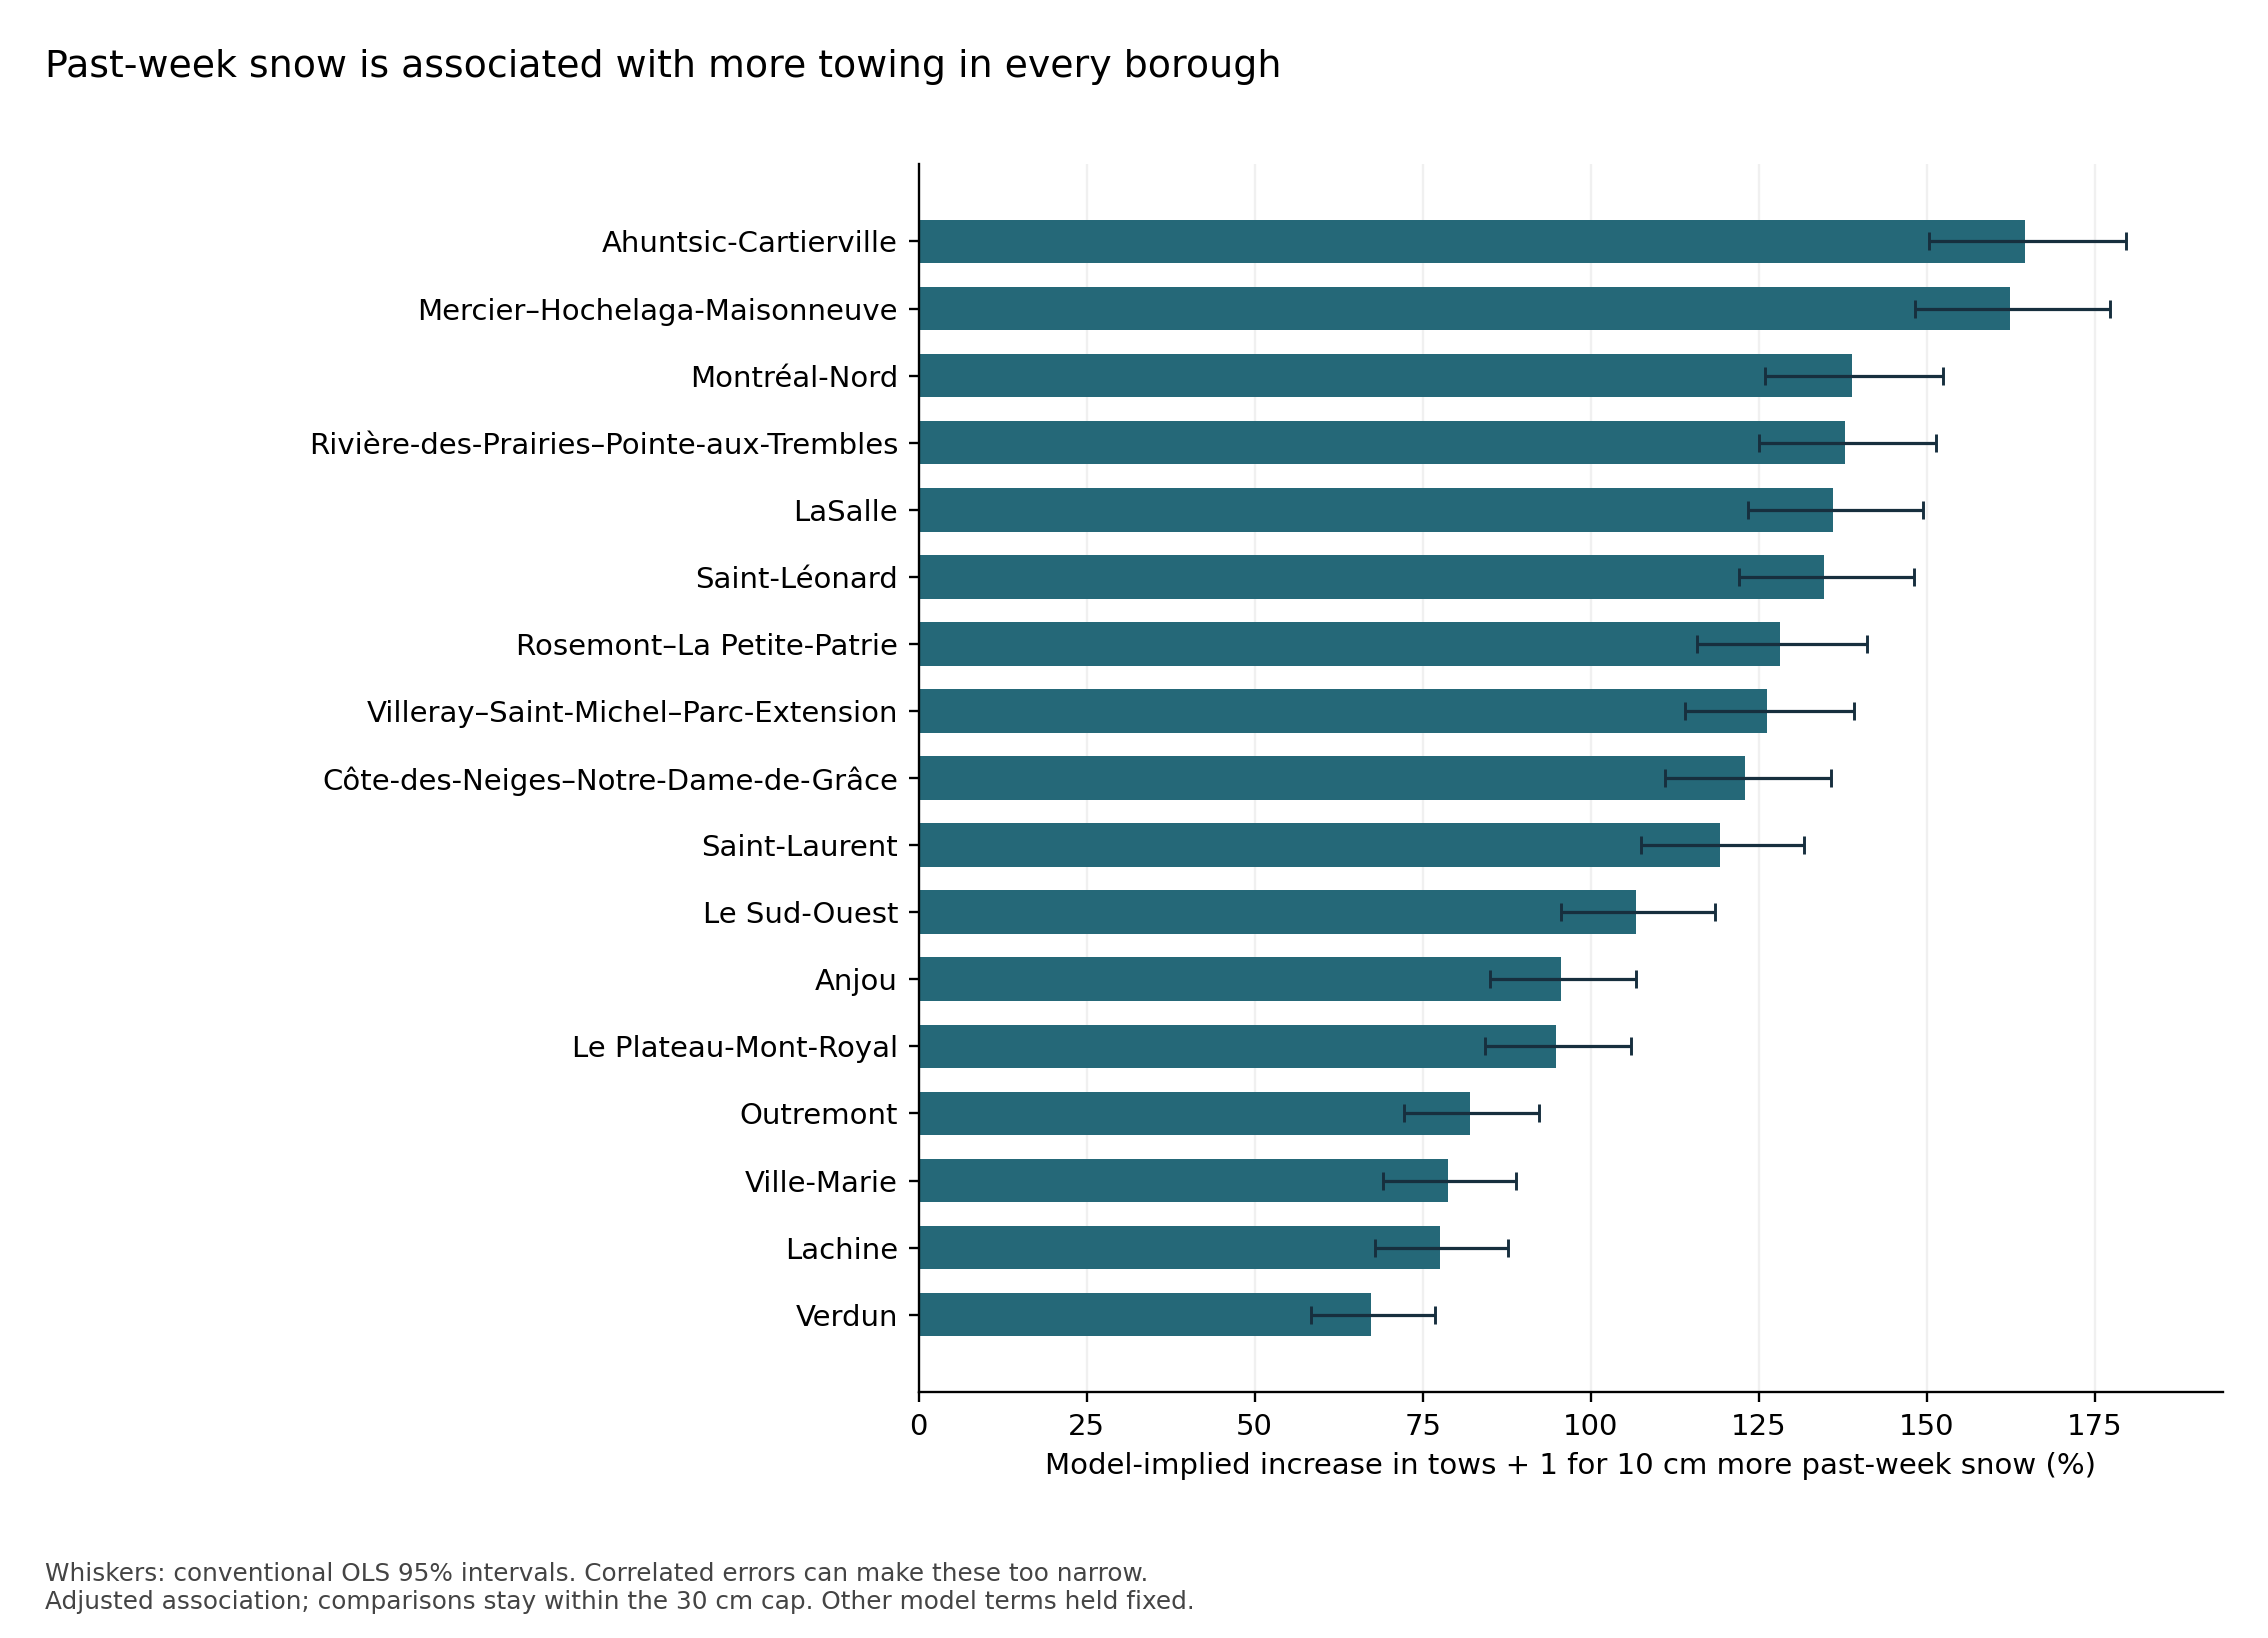

In [7]:
effect_rows = []
for b in boroughs:
    x0 = train.iloc[[0]].copy()
    x0['borough'] = b
    x0['snow_7c'] = 0.0
    x1 = x0.copy()
    x1['snow_7c'] = 1.0
    design_info = getattr(final.model.data,'design_info',None)
    if design_info is None: design_info = final.model.data.model_spec
    X0 = np.asarray(build_design_matrices([design_info],x0)[0])
    X1 = np.asarray(build_design_matrices([design_info],x1)[0])
    contrast = (X1-X0).ravel()
    row = {'borough':b}
    for label,fit in [('ols',final),('panel14',robust14),('panel28',robust28)]:
        tt = fit.t_test(contrast)
        slope = float(np.asarray(tt.effect).item())
        lo,hi = np.asarray(tt.conf_int()).ravel()
        row.update({f'slope_{label}':slope,f'se_{label}':float(np.asarray(tt.sd).item()),f'p_{label}':float(np.asarray(tt.pvalue).item()),f'pct_{label}':100*np.expm1(10*slope),f'pct_low_{label}':100*np.expm1(10*lo),f'pct_high_{label}':100*np.expm1(10*hi)})
    effect_rows.append(row)
effects = pd.DataFrame(effect_rows).sort_values('pct_ols',ascending=False).reset_index(drop=True)
effects.insert(0,'rank',np.arange(1,len(effects)+1))
effects.to_csv(OUT/'tables/borough_snow_effects.csv',index=False,encoding='utf-8-sig')
display(effects[['rank','borough','pct_ols','pct_low_ols','pct_high_ols','pct_low_panel14','pct_high_panel14']].round(1))

def effect_chart(robust=False):
    label = 'panel14' if robust else 'ols'
    fig,ax = plt.subplots(figsize=(10.8,7.8))
    y = np.arange(len(effects))
    ax.barh(y,effects.pct_ols,color='#256878',height=.65)
    ax.errorbar(effects.pct_ols,y,xerr=np.vstack([effects.pct_ols-effects[f'pct_low_{label}'],effects[f'pct_high_{label}']-effects.pct_ols]),fmt='none',ecolor='#172f3e',capsize=3,linewidth=1.1)
    ax.set_yticks(y,effects.borough)
    ax.invert_yaxis()
    ax.set_xlabel('Model-implied increase in tows + 1 for 10 cm more past-week snow (%)')
    fig.suptitle('Past-week snow is associated with more towing in every borough',x=.02,ha='left',fontsize=13,y=.97)
    ax.grid(axis='x',alpha=.18)
    ax.set_axisbelow(True)
    ax.set_xlim(0,float(effects[f'pct_high_{label}'].max())*1.08)
    fig.text(.02,.018,('Whiskers: 95% panel-robust intervals, 14-day bandwidth.' if robust else 'Whiskers: conventional OLS 95% intervals. Correlated errors can make these too narrow.')+'\nAdjusted association; comparisons stay within the 30 cm cap. Other model terms held fixed.',fontsize=8.5,color='#444444')
    fig.subplots_adjust(left=.405,right=.98,top=.90,bottom=.15)
    stem = 'borough_snow_effects_panel14' if robust else 'borough_snow_effects'
    fig.savefig(OUT/'figures'/f'{stem}.png',dpi=210)
    fig.savefig(OUT/'figures'/f'{stem}.svg')
    plt.close(fig)
effect_chart()
effect_chart(robust=True)
display(Image(filename=str(OUT/'figures/borough_snow_effects.png')))

## 7 Translate the snow contrast into extra cars

Absolute changes require an explicit baseline. Use the 121 December–March dates in the held-out year, retaining their calendar values and trend. Set past-week snow, snow 8–14 days ago, yesterday snow and rain to **0**, and past-week mean temperature to **0 °C**. Compare past-week snow of **0 vs 10 cm**, keeping yesterday snow at 0 (the added snow can have fallen on days 2–7). All other terms stay fixed.

For approximate mean counts, use each borough's `mean(exp(training residual))` smearing factor, estimated exclusively on training rows. Compute predicted counts as `max(smearing * exp(eta) - 1, 0)` for each scenario and average their difference over those winter calendar dates. These are model-based scenario estimates of extra **cars per borough-day**, conditional on the retransformation assumption. They are not observed storm effects or forecasts for a particular operation. The CSV also includes uncorrected retransformation values so D can assess sensitivity.

,borough,pred_tows_snow0,pred_tows_snow10,extra_tows,uncorrected_extra_tows,training_smearing_factor,pct_ols
5,Le Plateau-Mont-Royal,9.06,18.60,9.54,5.31,1.80,94.82
15,Ville-Marie,10.82,20.11,9.30,5.14,1.81,78.70
11,Rosemont–La Petite-Patrie,5.97,14.89,8.93,5.18,1.72,128.13
16,Villeray–Saint-Michel–Parc-Extension,5.39,13.45,8.06,5.09,1.58,126.25
2,Côte-des-Neiges–Notre-Dame-de-Grâce,5.25,12.93,7.68,4.58,1.68,122.99
7,Mercier–Hochelaga-Maisonneuve,3.08,9.69,6.62,4.03,1.64,162.33
0,Ahuntsic-Cartierville,2.83,9.12,6.30,3.77,1.67,164.56
6,Le Sud-Ouest,4.60,10.57,5.97,3.53,1.69,106.72
8,Montréal-Nord,1.91,5.95,4.04,2.60,1.56,138.83
13,Saint-Léonard,1.49,4.85,3.36,1.97,1.70,134.66


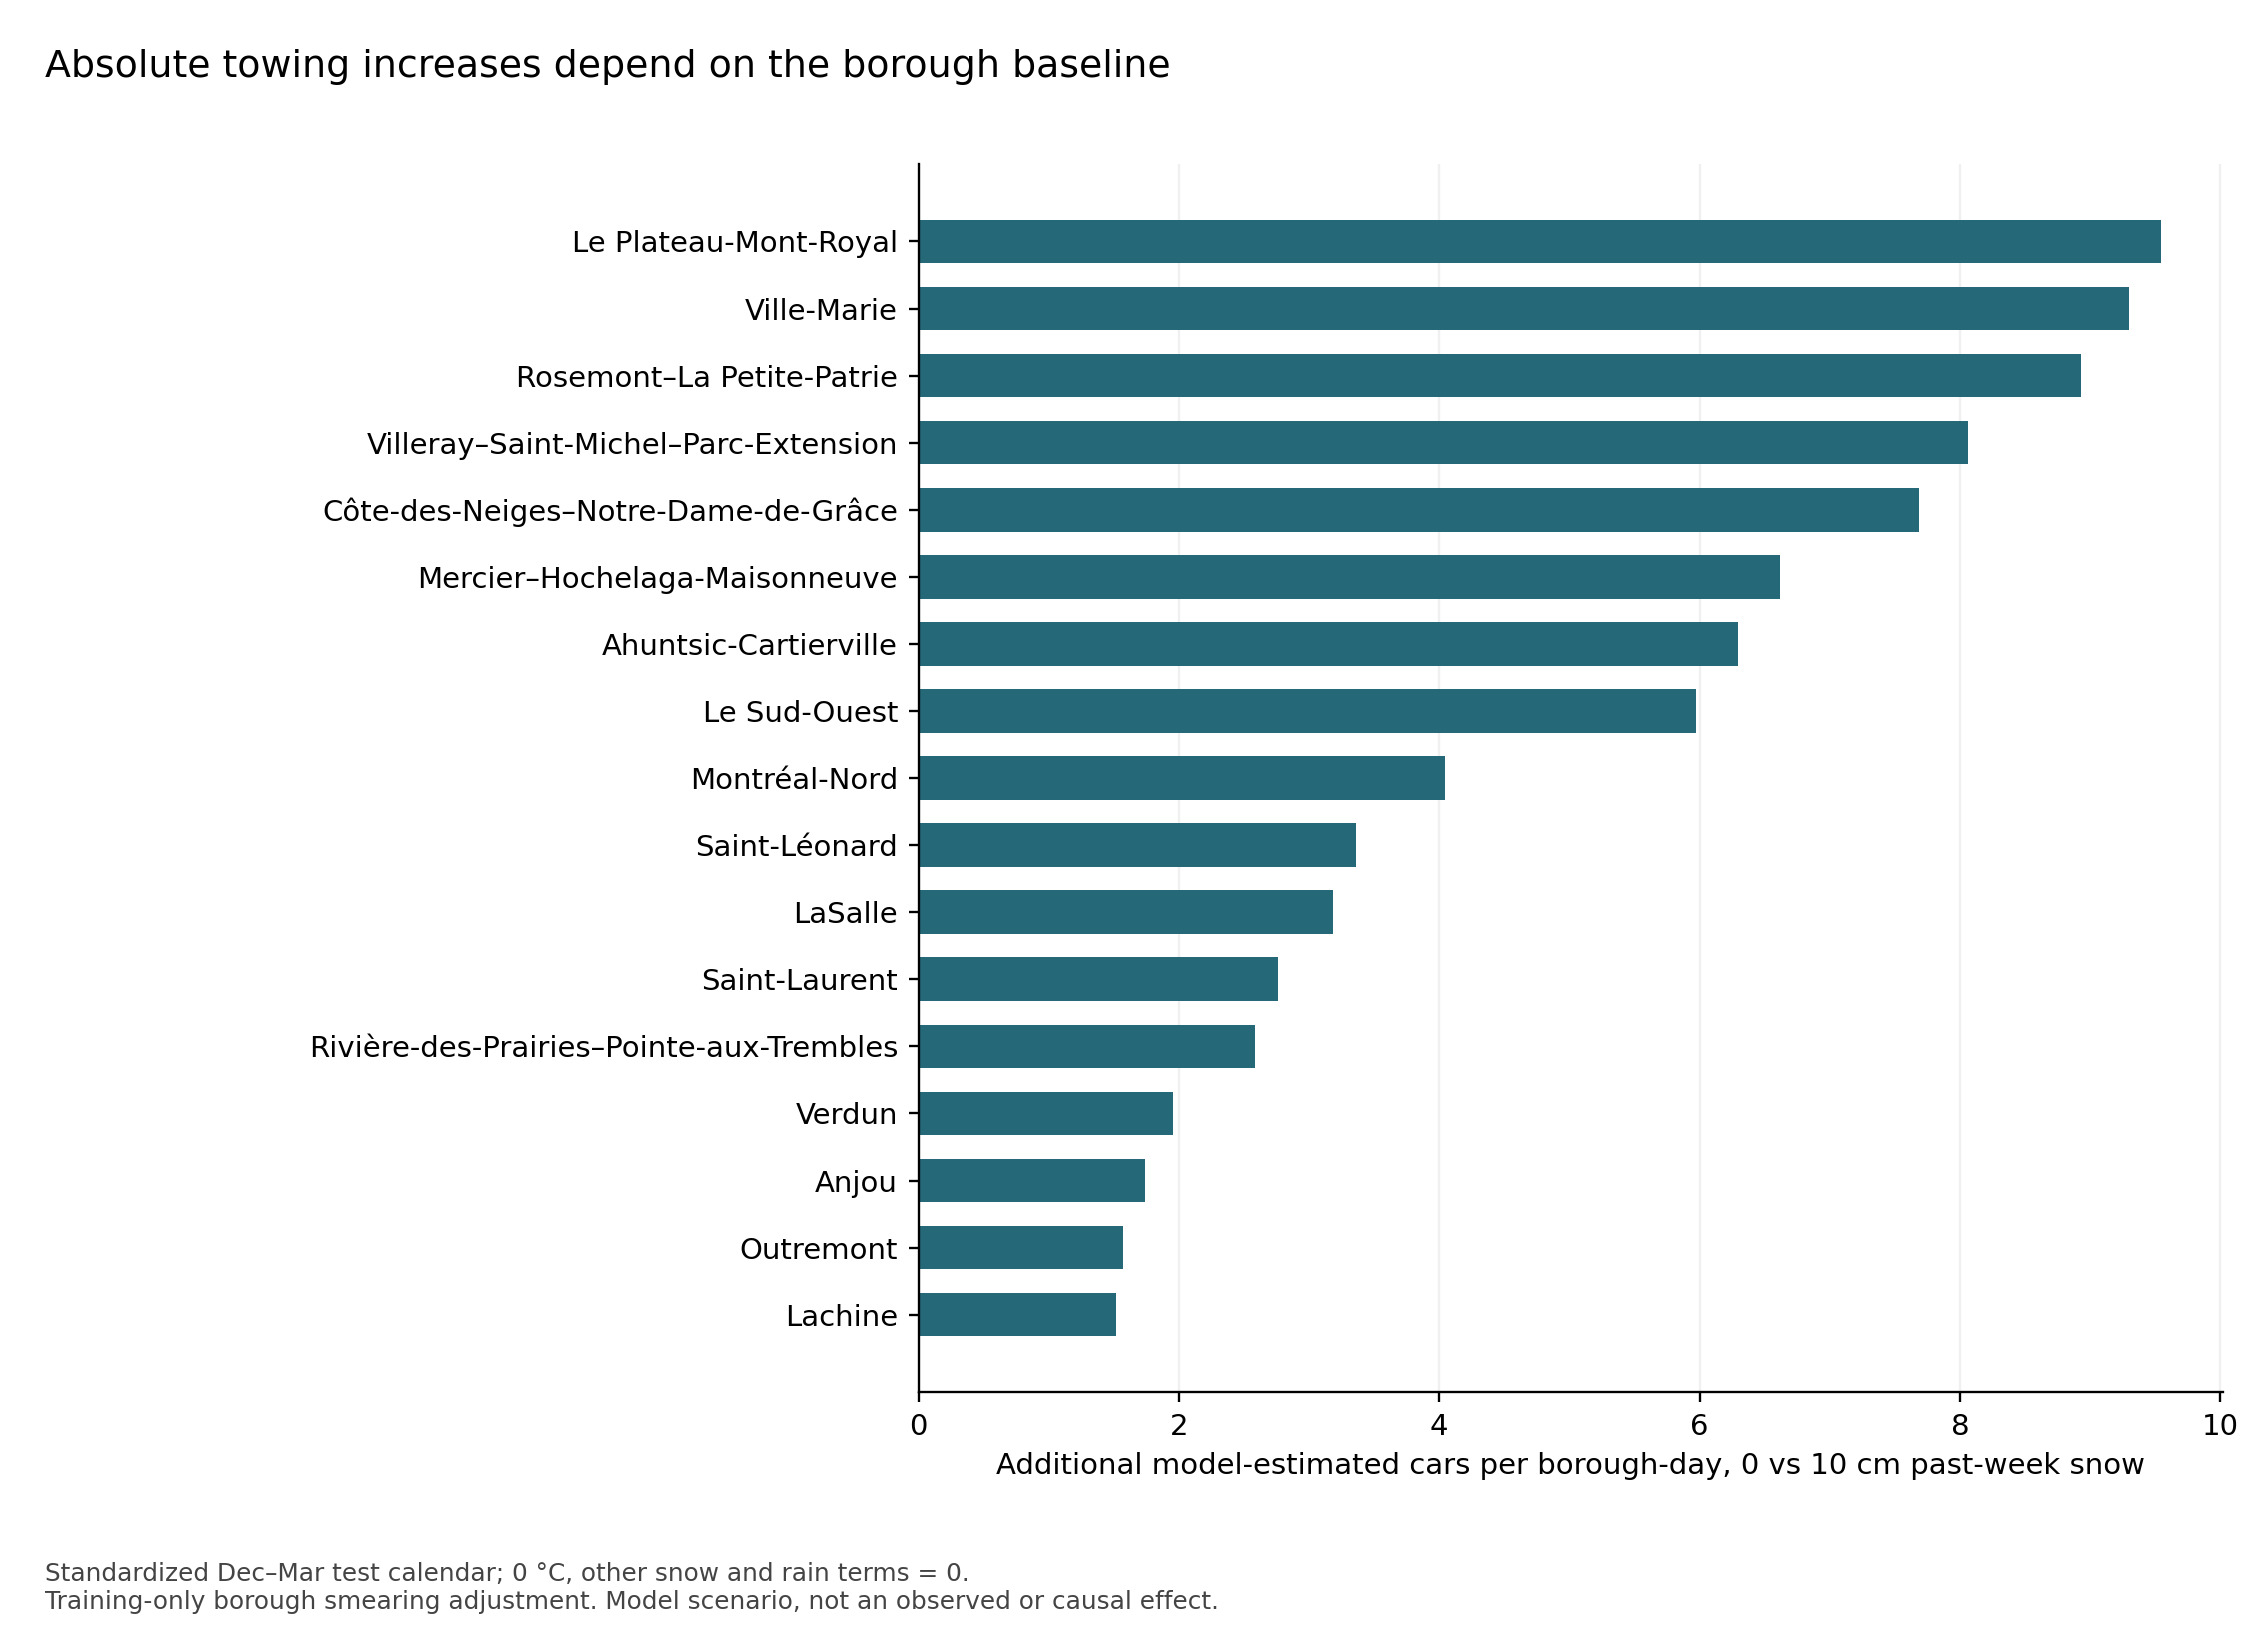

In [8]:
winter_test = test.loc[test.month.isin([12,1,2,3])].copy()
assert winter_test.date.nunique() == 121
baseline = winter_test.copy()
for c in weather_cols: baseline[c] = 0.0
plus10 = baseline.copy()
plus10['snow_7c'] = 10.0
eta0,eta10 = final.predict(baseline),final.predict(plus10)
factor = baseline.borough.map(smear_by_model['M3 Borough snow slopes'])
scenario = baseline[['date','borough']].copy()
scenario['pred_tows_snow0'] = np.maximum(factor*np.exp(eta0)-1,0)
scenario['pred_tows_snow10'] = np.maximum(factor*np.exp(eta10)-1,0)
scenario['extra_tows'] = scenario.pred_tows_snow10-scenario.pred_tows_snow0
scenario['uncorrected_extra_tows'] = np.maximum(np.expm1(eta10),0)-np.maximum(np.expm1(eta0),0)
cars = scenario.groupby('borough')[['pred_tows_snow0','pred_tows_snow10','extra_tows','uncorrected_extra_tows']].mean().reset_index()
cars['training_smearing_factor'] = cars.borough.map(smear_by_model['M3 Borough snow slopes'])
cars = cars.merge(effects[['borough','pct_ols']],on='borough',validate='one_to_one').sort_values('extra_tows',ascending=False)
cars.to_csv(OUT/'tables/extra_cars_scenario.csv',index=False,encoding='utf-8-sig')
display(cars.round(2))
fig,ax = plt.subplots(figsize=(10.8,7.8))
y = np.arange(len(cars))
ax.barh(y,cars.extra_tows,color='#256878',height=.65)
ax.set_yticks(y,cars.borough)
ax.invert_yaxis()
ax.set_xlabel('Additional model-estimated cars per borough-day, 0 vs 10 cm past-week snow')
fig.suptitle('Absolute towing increases depend on the borough baseline',x=.02,ha='left',fontsize=13,y=.97)
ax.grid(axis='x',alpha=.18)
ax.set_axisbelow(True)
fig.text(.02,.018,'Standardized Dec–Mar test calendar; 0 °C, other snow and rain terms = 0.\nTraining-only borough smearing adjustment. Model scenario, not an observed or causal effect.',fontsize=8.5,color='#444444')
fig.subplots_adjust(left=.405,right=.98,top=.90,bottom=.15)
fig.savefig(OUT/'figures/extra_cars_scenario.png',dpi=210)
fig.savefig(OUT/'figures/extra_cars_scenario.svg')
plt.close(fig)
display(Image(filename=str(OUT/'figures/extra_cars_scenario.png')))

## 8 Check the temperature repair and prepare D's handoff

Refit the final specification using the supplied interpolated temperature only as a sensitivity check. Compare it with the past-only main model. Hand D the fitted training model, input, predictions, MASE denominators, and exact forecast definitions. D owns the test-year benchmark comparison, rolling checks and full residual diagnostics.

In [9]:
original_train = data_original.loc[data_original.date <= '2025-06-30'].copy()
original_test = data_original.loc[data_original.date >= '2025-07-01'].copy()
original_train['log_tows'] = np.log1p(original_train.tows)
original_fit = smf.ols(final_formula,data=original_train).fit()
original_pred = np.maximum(np.expm1(original_fit.predict(original_test)),0)
original_mae = pd.DataFrame({'borough':original_test.borough,'abs_error':np.abs(original_test.tows-original_pred)}).groupby('borough').abs_error.mean()
original_mase = (original_mae/scales).mean()
sensitivity = pd.DataFrame([
    {'temperature':'past-only fill (main)','training_r2':final.rsquared,'test_mase':float(ladder.loc[ladder.model.eq('M3 Borough snow slopes'),'test_mase'].iloc[0])},
    {'temperature':'Part A interpolation (sensitivity)','training_r2':original_fit.rsquared,'test_mase':original_mase}
])
sensitivity.to_csv(OUT/'tables/temperature_model_sensitivity.csv',index=False)
display(sensitivity.round(5))
# Preserve Patsy formula metadata. Load pickles only from trusted sources.
for name,model in models.items():
    model.save(str(OUT/'handoff'/f'{name[:2].lower()}_model.pkl'))
manifest = {
    'source_sha256': hashlib.sha256(SOURCE.read_bytes()).hexdigest(),
    'source':'data/processed/tow_risk_clean.csv',
    'model_input':'part_c/handoff/model_input.csv',
    'train_start':'2021-01-01','train_end':'2025-06-30','test_start':'2025-07-01','test_end':'2026-06-30',
    'train_rows':len(train),'test_rows':len(test),'boroughs':len(boroughs),
    'formulas':formulas,'versions':versions,'temperature_dates_changed':int(changed.sum()),
    'temperature_train_dates_changed':int(changed.loc[:'2025-06-30'].sum()),
    'temperature_test_dates_changed':int(changed.loc['2025-07-01':].sum()),
    'primary_inverse':'max(expm1(predicted log(tows+1)), 0)',
    'secondary_inverse':'max(exp(predicted log(tows+1)) * borough mean(exp(training residual)) - 1, 0)',
    'mase':'Borough test MAE divided by its training mean absolute lag-7 difference; overall mean of 17 borough MASEs',
    'intervals':'Primary conventional OLS; supplementary hac-groupsum, Bartlett, 14 and 28 daily lags',
    'extra_cars_scenario':'Dec–Mar test dates; snow_7c 0 vs 10, other weather terms 0; train-only borough smearing; average cars per borough-day',
    'joint_interaction_test':joint_test
}
(OUT/'handoff/analysis_manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')
print('Final training R-squared:',round(final.rsquared,4))
print('Largest relative snow association:',effects.iloc[0].borough,round(effects.iloc[0].pct_ols,1),'%')
print('Smallest relative snow association:',effects.iloc[-1].borough,round(effects.iloc[-1].pct_ols,1),'%')
print('Largest extra-cars scenario:',cars.iloc[0].borough,round(cars.iloc[0].extra_tows,2),'cars per day')
print('All analysis tables, figures, model input and D handoff files saved under',OUT)

,temperature,training_r2,test_mase
0,past-only fill (main),0.48227,0.96816
1,Part A interpolation (sensitivity),0.48226,0.96815


Final training R-squared: 0.4823
Largest relative snow association: Ahuntsic-Cartierville 164.6 %
Smallest relative snow association: Verdun 67.3 %
Largest extra-cars scenario: Le Plateau-Mont-Royal 9.54 cars per day
All analysis tables, figures, model input and D handoff files saved under C:\Users\tonyt\Downloads\Tow_Risk_Project\Tow_Risk_Project\part_c


## 9 Interpretation and limits

- Compare M1, M2 and M3 on the same held-out year. A larger training R² does not guarantee a lower test MASE. Keep M3 for the planned borough-slope explanation even if M2 forecasts slightly better.
- Snow effects describe an adjusted statistical association. Clearing decisions and other omitted factors can affect it. The model cannot identify a street, an operation start, or a driver's towing probability.
- The supplied snow and rain gaps were filled with zero by Part A. The temperature audit repairs its interpolation look-ahead. It does not reconstruct unknown historical weather values or issue times.
- Percentage changes are on the tows + 1 scale. Consult the absolute scenario table when discussing car volumes.
- The conventional intervals assume independent errors and may be narrow. Use the panel-robust results to qualify apparent ranking differences, especially in the middle.
- Every borough shares one weather station. The capped snow model is linear only up to 30 cm. The smearing alternative assumes its training residual adjustment transfers to the test period.
- D should compare both benchmarks on the test year and run the rolling and diagnostic checks specified in Step 5. Their results are not assumed here.

**Sources:** the supplied final analysis plan (Step 4); `Part_A_Tow_Risk.ipynb`; `data/processed/tow_risk_clean.csv`; the seven supplied weather CSVs; supplied `remorquages.csv` for count reconciliation. Method references are linked beside MASE and robust covariance above.